# Visualização de Resultados PREDEP — Bacia do Uruguai por Cluster

Notebook equivalente ao `plot_predep_results.ipynb`, adaptado para clusters.  
Os **mesmos gráficos** são gerados: `plot_4x4_optimal_lags` e `plot_12x4_all_lags`,  
com **colunas = estações (DJF, MAM, JJA, SON)** e um plot por MoV.  
Cada célula exibe o mapa espacial da bacia com clusters coloridos pelo α — idêntico aos mapas do experimento 02.

In [37]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import netCDF4 as nc4
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.gridspec import GridSpec
from pathlib import Path

plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'sans-serif'

RESULTS_DIR = Path('../results/predep_uruguai')
MASKS_FILE  = Path('../data/processed/uruguai_cluster_masks.npz')
SEASONS     = ['DJF', 'MAM', 'JJA', 'SON']
N_LAGS      = 12  # lags 1–12

mov_dirs = sorted([
    d.name for d in RESULTS_DIR.iterdir()
    if d.is_dir() and any(d.glob('*_predep_clusters_seasonal.nc'))
])
print(f'MoVs disponíveis ({len(mov_dirs)}): {mov_dirs}')

MoVs disponíveis (1): ['AAO']


## 1. Carregar Resultados e Máscaras Espaciais

In [38]:
# ── Máscaras de cluster → grid espacial ──────────────────────────────────────
npz         = np.load(str(MASKS_FILE), allow_pickle=True)
mask_cnames = list(npz['cluster_names'])   # ordem no NPZ
masks_flat  = npz['masks_flat'].astype(bool)  # (n_clusters, n_pts)
lats        = npz['lats']
lons        = npz['lons']
n_lat       = len(lats)
n_lon       = len(lons)
print(f'Máscaras: {masks_flat.shape}  grid {n_lat}×{n_lon}')
print(f'Clusters (ordem NPZ): {mask_cnames}')
print(f'Pts por cluster: {masks_flat.sum(axis=1)}')

# ── Resultados PREDEP ─────────────────────────────────────────────────────────
def load_mov(mov_name):
    """
    Retorna (cluster_names, alpha) onde alpha.shape = (n_seasons, n_clusters, N_LAGS).
    A ordem dos clusters segue o NC, não necessariamente o NPZ.
    """
    nc_file = RESULTS_DIR / mov_name / f'{mov_name}_predep_clusters_seasonal.nc'
    if not nc_file.exists():
        return None, None
    with nc4.Dataset(str(nc_file)) as nc:
        cnames = [
            c.decode() if isinstance(c, bytes) else str(c)
            for c in nc.variables['cluster'][:]
        ]
        seasons_nc = [
            s.decode() if isinstance(s, bytes) else str(s)
            for s in nc.variables['season'][:]
        ]
        raw   = nc.variables['alpha'][:]                 # masked (n_seasons, n_clusters, N_LAGS)
        alpha = np.ma.filled(raw, np.nan).astype(float)
    # Reordenar estações para SEASONS
    idx   = [seasons_nc.index(s) for s in SEASONS if s in seasons_nc]
    alpha = alpha[idx]
    return cnames, alpha


all_data      = {}   # mov_name → alpha (n_seasons, n_clusters, N_LAGS)
cluster_names = None

for mov in mov_dirs:
    cnames, alpha = load_mov(mov)
    if alpha is not None:
        all_data[mov] = alpha
        if cluster_names is None:
            cluster_names = cnames
        total_nan = np.isnan(alpha).sum()
        print(f'  {mov}: shape={alpha.shape}  '
              f'max={np.nanmax(alpha):.3f}  nan={total_nan}/{alpha.size}')

n_clusters = len(cluster_names)
short_names = [
    c.replace('_URUGUAI', '').replace('CLUSTER', 'C')
    for c in cluster_names
]

# Índice: cluster_name → linha em masks_flat (ordem pode diferir entre NC e NPZ)
mask_idx = {name: mask_cnames.index(name) for name in cluster_names if name in mask_cnames}

print(f'\nClusters ({n_clusters}): {short_names}')
print(f'MoVs carregados: {len(all_data)}')


def make_alpha_map(alpha_vals, cluster_names, mask_idx, masks_flat, n_lat, n_lon):
    """
    Rasteriza um vetor de α por cluster num mapa 2D (n_lat, n_lon).
    Pixels fora de qualquer cluster ficam NaN.
    alpha_vals: (n_clusters,) — um α por cluster
    """
    alpha_map = np.full((n_lat, n_lon), np.nan)
    for ci, cname in enumerate(cluster_names):
        if cname not in mask_idx:
            continue
        m2d = masks_flat[mask_idx[cname]].reshape(n_lat, n_lon)
        alpha_map[m2d] = alpha_vals[ci]
    return alpha_map

Máscaras: (4, 6138)  grid 66×93
Clusters (ordem NPZ): ['CLUSTER1_URUGUAI', 'CLUSTER2_URUGUAI', 'CLUSTER4_URUGUAI', 'CLUSTER3_URUGUAI']
Pts por cluster: [514 395 275 420]
  AAO: shape=(4, 4, 12)  max=0.803  nan=0/192

Clusters (4): ['C1', 'C2', 'C4', 'C3']
MoVs carregados: 1


## 2. Funções de Plot

Adaptações diretas de `plot_4x4_optimal_lags` e `plot_12x4_all_lags`  
de `src/visualization/predep_plots.py`.  
Cada célula exibe o **mapa espacial** da bacia com os clusters coloridos pelo valor de α —  
idêntico aos mapas lat×lon do experimento 02.

In [39]:
def plot_4x4_optimal_lags_clusters(alpha, mov_name, cluster_names, output_dir):
    """
    4 linhas × 4 colunas (DJF, MAM, JJA, SON).
      Linha 1: α máximo por cluster — mapa espacial
      Linhas 2-4: lag do 1°/2°/3° maior α — mapa espacial
    alpha shape: (n_seasons, n_clusters, N_LAGS)  — índice 0 = lag 1, ..., N_LAGS-1 = lag 12
    """
    n_c    = len(cluster_names)
    n_cols = len(SEASONS)
    LAGS   = list(range(1, N_LAGS + 1))   # [1, 2, ..., 12]

    fig = plt.figure(figsize=(5 * n_cols, 22))
    gs  = GridSpec(4, n_cols + 1, figure=fig,
                   width_ratios=[1] * n_cols + [0.05],
                   hspace=0.25, wspace=0.15,
                   left=0.05, right=0.95, top=0.94, bottom=0.05)

    levels_alpha   = np.arange(0.0, 1.1, 0.1)
    norm_alpha     = BoundaryNorm(levels_alpha, ncolors=plt.cm.jet.N, clip=True)
    lag_boundaries = np.arange(0.5, N_LAGS + 1.5, 1.0)   # 0.5 … 12.5
    lag_norm       = BoundaryNorm(lag_boundaries, ncolors=plt.cm.jet.N, clip=True)

    im_alpha = None
    im_lag   = None

    for col, season in enumerate(SEASONS):
        a = alpha[col]   # (n_clusters, N_LAGS)

        # Ordenar índices de array (0-based) por α decrescente
        order     = np.argsort(np.where(np.isnan(a), -999.0, a), axis=1)[:, ::-1]
        alpha_max = a[np.arange(n_c), order[:, 0]].copy()
        # Converter índice 0-based → lag real (1-based)
        lag_1st   = (order[:, 0] + 1).astype(float)
        lag_2nd   = (order[:, 1] + 1).astype(float)
        lag_3rd   = (order[:, 2] + 1).astype(float)

        all_nan = np.all(np.isnan(a), axis=1)
        for arr in (alpha_max, lag_1st, lag_2nd, lag_3rd):
            arr[all_nan] = np.nan

        rows_data = [
            (alpha_max, norm_alpha, f'{season} - α máximo'),
            (lag_1st,   lag_norm,   f'{season} - Lag 1°'),
            (lag_2nd,   lag_norm,   f'{season} - Lag 2°'),
            (lag_3rd,   lag_norm,   f'{season} - Lag 3°'),
        ]

        for row, (vals, norm, title) in enumerate(rows_data):
            ax      = fig.add_subplot(gs[row, col])
            amap    = make_alpha_map(vals, cluster_names, mask_idx,
                                     masks_flat, n_lat, n_lon)
            im = ax.imshow(amap, cmap='jet', norm=norm,
                           aspect='auto', origin='lower',
                           interpolation='nearest')
            ax.axis('off')

            if row == 0:
                ax.set_title(season, fontsize=12, fontweight='bold')

            for ci, cname in enumerate(cluster_names):
                if cname not in mask_idx or np.isnan(vals[ci]):
                    continue
                m2d = masks_flat[mask_idx[cname]].reshape(n_lat, n_lon)
                rows_m, cols_m = np.where(m2d)
                cy, cx = rows_m.mean(), cols_m.mean()
                txt = f'{vals[ci]:.2f}' if row == 0 else f'{int(vals[ci])}'
                color = 'white' if (row == 0 and vals[ci] > 0.5) else 'black'
                ax.text(cx, cy, txt, ha='center', va='center',
                        fontsize=8, fontweight='bold', color=color)

            if row == 0 and im_alpha is None:
                im_alpha = im
            if row == 1 and im_lag is None:
                im_lag = im

    cbar_ax1 = fig.add_subplot(gs[0, n_cols])
    cbar1 = fig.colorbar(im_alpha, cax=cbar_ax1,
                         ticks=np.arange(0.0, 1.1, 0.1))
    cbar1.set_label('α', fontsize=12, fontweight='bold')

    cbar_ax2 = fig.add_subplot(gs[1:4, n_cols])
    cbar2 = fig.colorbar(im_lag, cax=cbar_ax2, ticks=LAGS)
    cbar2.set_label('Lag (meses)', fontsize=12, fontweight='bold')

    plt.suptitle(
        f'Lags Ótimos por Estação — Clusters da Bacia do Uruguai: {mov_name}\n'
        f'Linha 1: α máximo | Linhas 2–4: Lags do 1°, 2° e 3° maiores α',
        fontsize=14, fontweight='bold'
    )

    out = output_dir / f'optimal_lag_seasons_{mov_name}.png'
    plt.savefig(out, dpi=200, bbox_inches='tight')
    plt.close()
    print(f'Plot salvo: {out}')
    return out


def plot_12x4_all_lags_clusters(alpha, mov_name, cluster_names, output_dir):
    """
    N_LAGS linhas (Lag 1 … Lag 12) × 4 colunas (DJF, MAM, JJA, SON).
    Cada célula: mapa espacial dos clusters coloridos por α.
    alpha shape: (n_seasons, n_clusters, N_LAGS)  — índice 0 = lag 1
    """
    n_cols = len(SEASONS)
    LAGS   = list(range(1, N_LAGS + 1))

    fig = plt.figure(figsize=(3 * n_cols, 30))
    gs  = GridSpec(N_LAGS, n_cols + 1, figure=fig,
                   width_ratios=[1] * n_cols + [0.05],
                   hspace=0.05, wspace=0.05,
                   left=0.08, right=0.95, top=0.96, bottom=0.02)

    levels = np.arange(0.0, 1.1, 0.1)
    cmap   = plt.cm.jet
    norm   = BoundaryNorm(levels, ncolors=cmap.N, clip=True)

    im = None
    for li, lag in enumerate(LAGS):   # li = índice 0-based, lag = 1-based
        for col, season in enumerate(SEASONS):
            ax   = fig.add_subplot(gs[li, col])
            vals = alpha[col, :, li]   # (n_clusters,)
            amap = make_alpha_map(vals, cluster_names, mask_idx,
                                  masks_flat, n_lat, n_lon)

            im = ax.imshow(amap, cmap=cmap, norm=norm,
                           aspect='auto', origin='lower',
                           interpolation='nearest')
            ax.axis('off')

            if li == 0:
                ax.set_title(season, fontsize=11, fontweight='bold', pad=3)

            if col == 0:
                ax.text(-0.15, 0.5, f'Lag {lag}',
                        transform=ax.transAxes,
                        rotation=90, va='center', ha='center',
                        fontsize=9, fontweight='bold')

    cbar_ax = fig.add_subplot(gs[:, n_cols])
    cbar = fig.colorbar(im, cax=cbar_ax, ticks=levels)
    cbar.set_label(
        'α (Predictive Dependence)\n0=Independente, 1=Perfeito',
        fontsize=10, fontweight='bold'
    )

    plt.suptitle(
        f'PREDEP α — Clusters da Bacia do Uruguai: {mov_name}\n'
        f'Linhas = Lags (1–{N_LAGS} meses) | Colunas = Estações (DJF, MAM, JJA, SON)',
        fontsize=14, fontweight='bold', y=0.99
    )

    out = output_dir / f'predep_all_lags_seasons_{mov_name}.png'
    plt.savefig(out, dpi=200, bbox_inches='tight')
    plt.close()
    print(f'Plot salvo: {out}')
    return out

## 3. Gerar Plots — Lags Ótimos (equiv. `plot_4x4_optimal_lags`)

Gerando plot lags ótimos: AAO...
Plot salvo: ../results/predep_uruguai/plots/optimal_lag_seasons_AAO.png


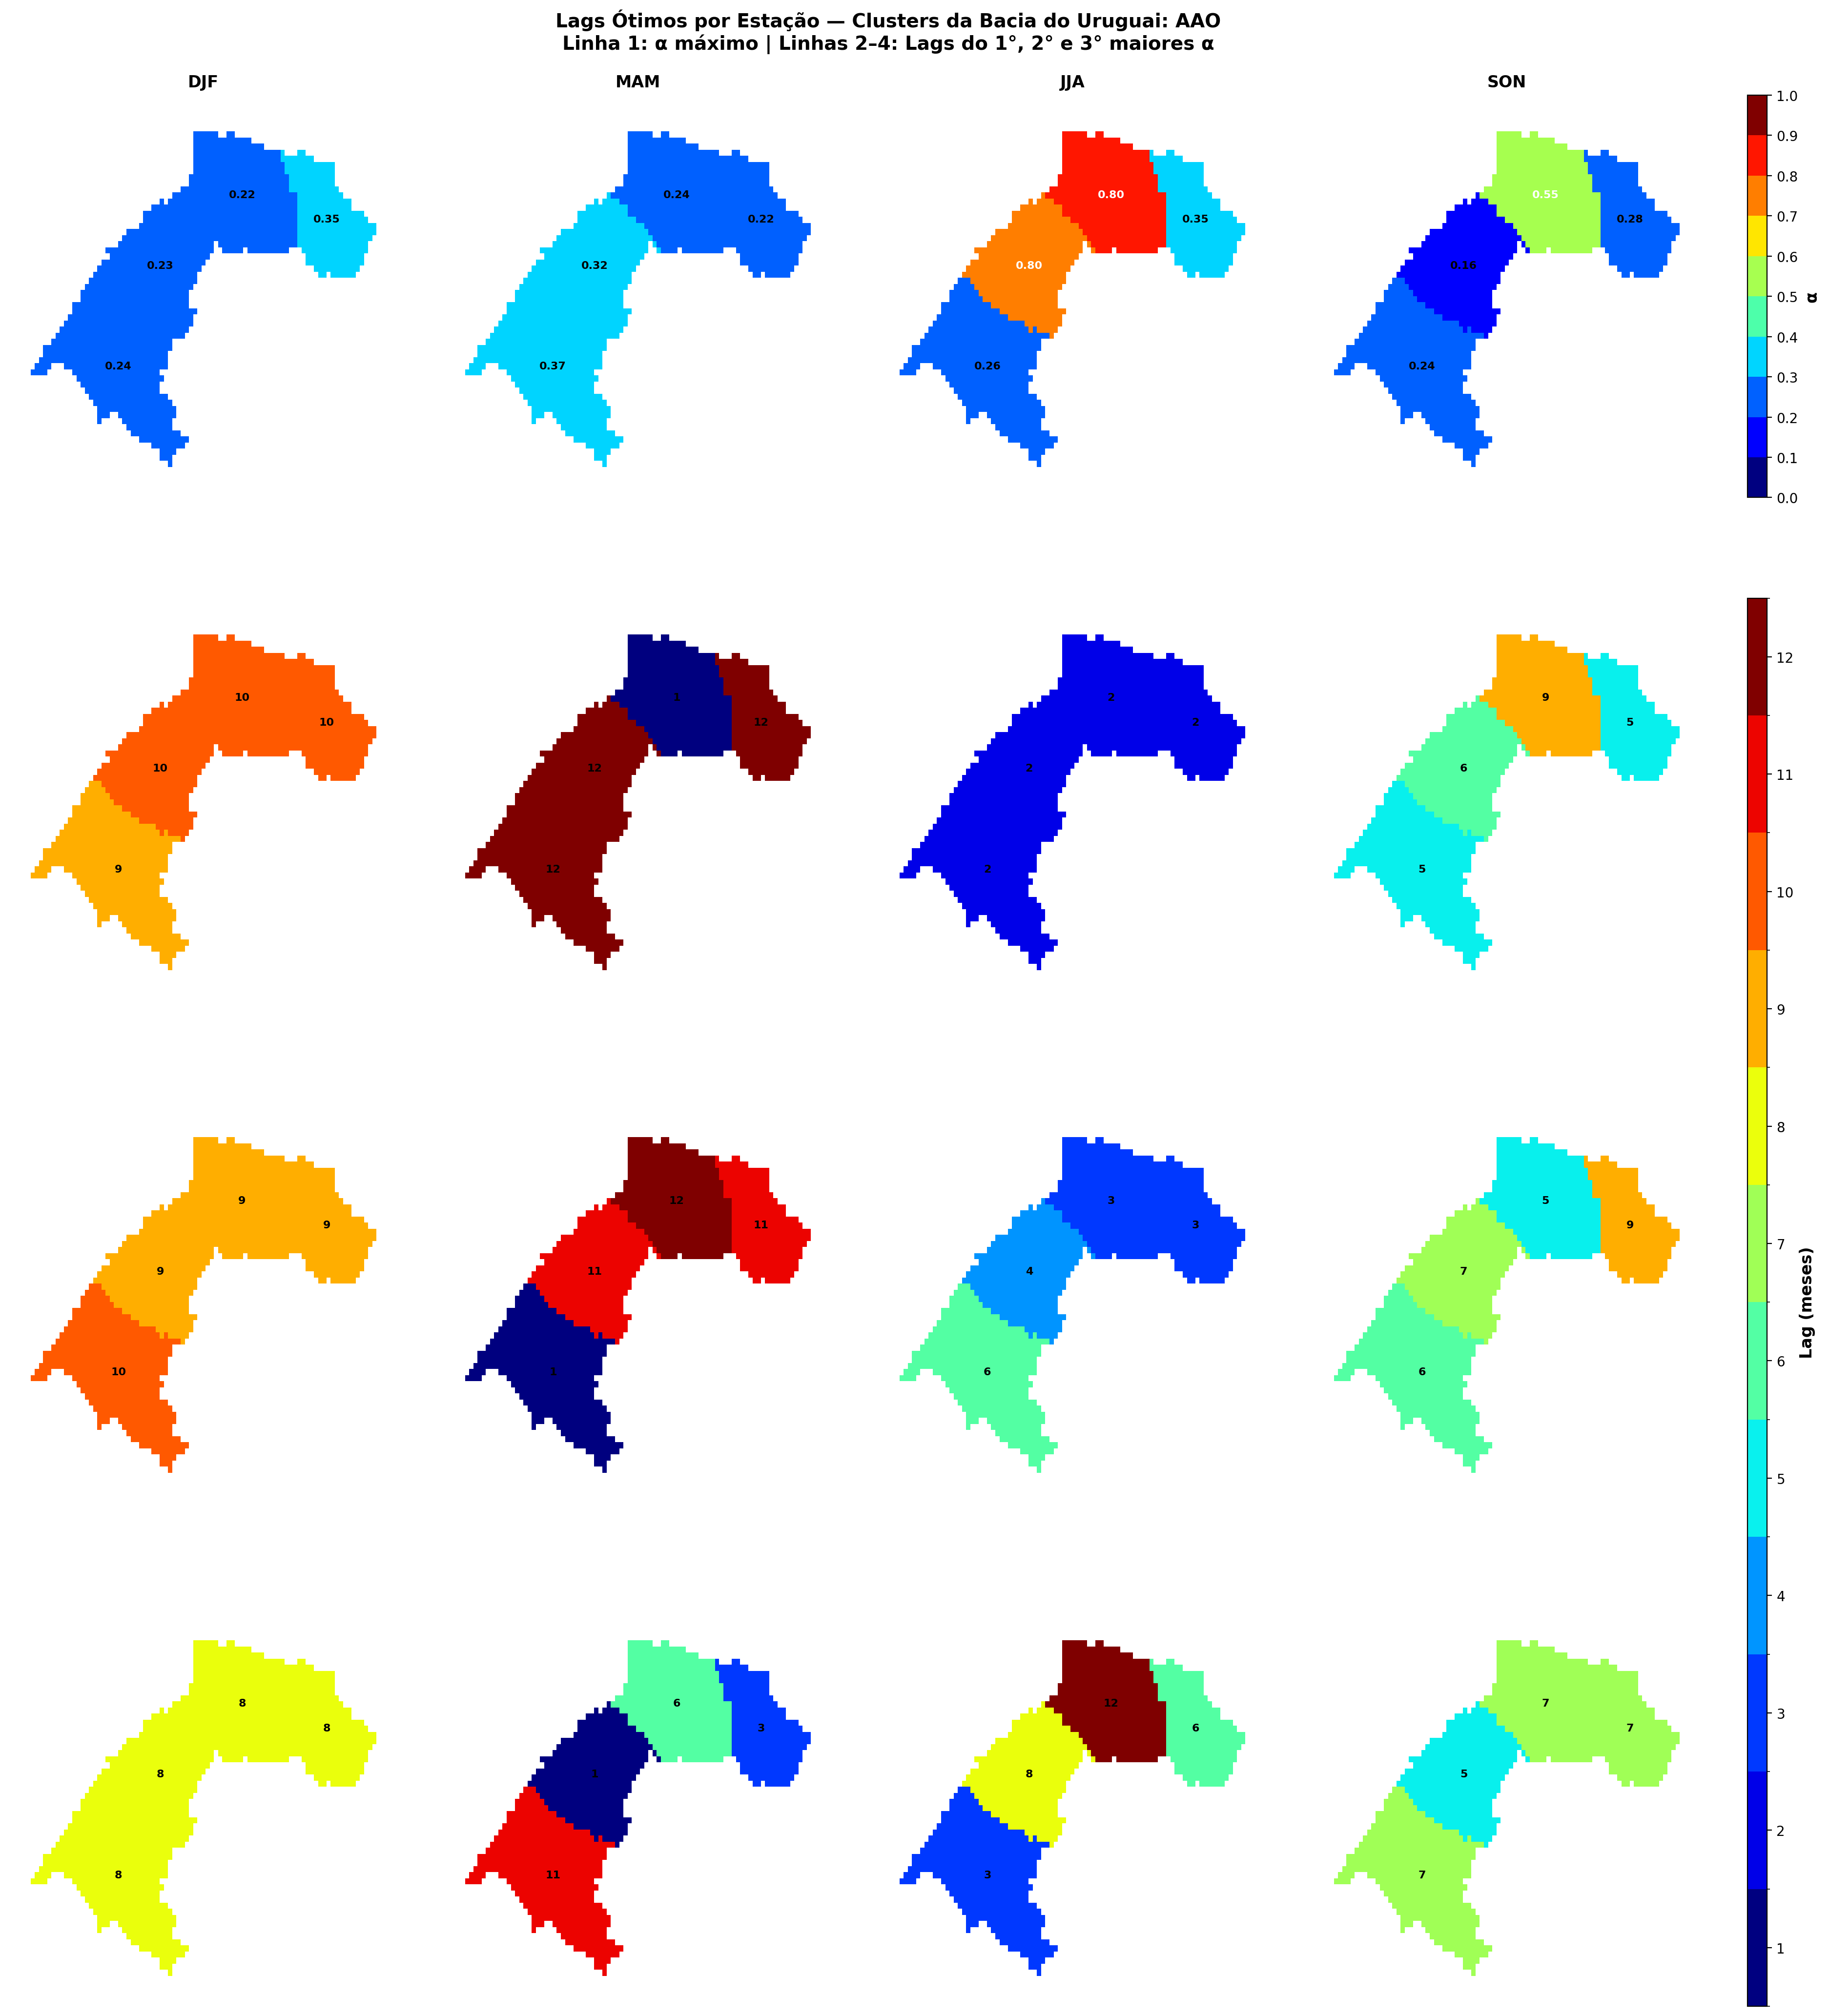

In [40]:
from IPython.display import Image, display

output_dir = RESULTS_DIR / 'plots'
output_dir.mkdir(exist_ok=True)

outs_4x4 = {}
for mov, alpha in all_data.items():
    print(f'Gerando plot lags ótimos: {mov}...')
    out = plot_4x4_optimal_lags_clusters(alpha, mov, cluster_names, output_dir)
    outs_4x4[mov] = out
    display(Image(filename=str(out)))

## 4. Gerar Plots — Todos os Lags (equiv. `plot_12x4_all_lags`)

Gerando plot todos os lags: AAO...
Plot salvo: ../results/predep_uruguai/plots/predep_all_lags_seasons_AAO.png


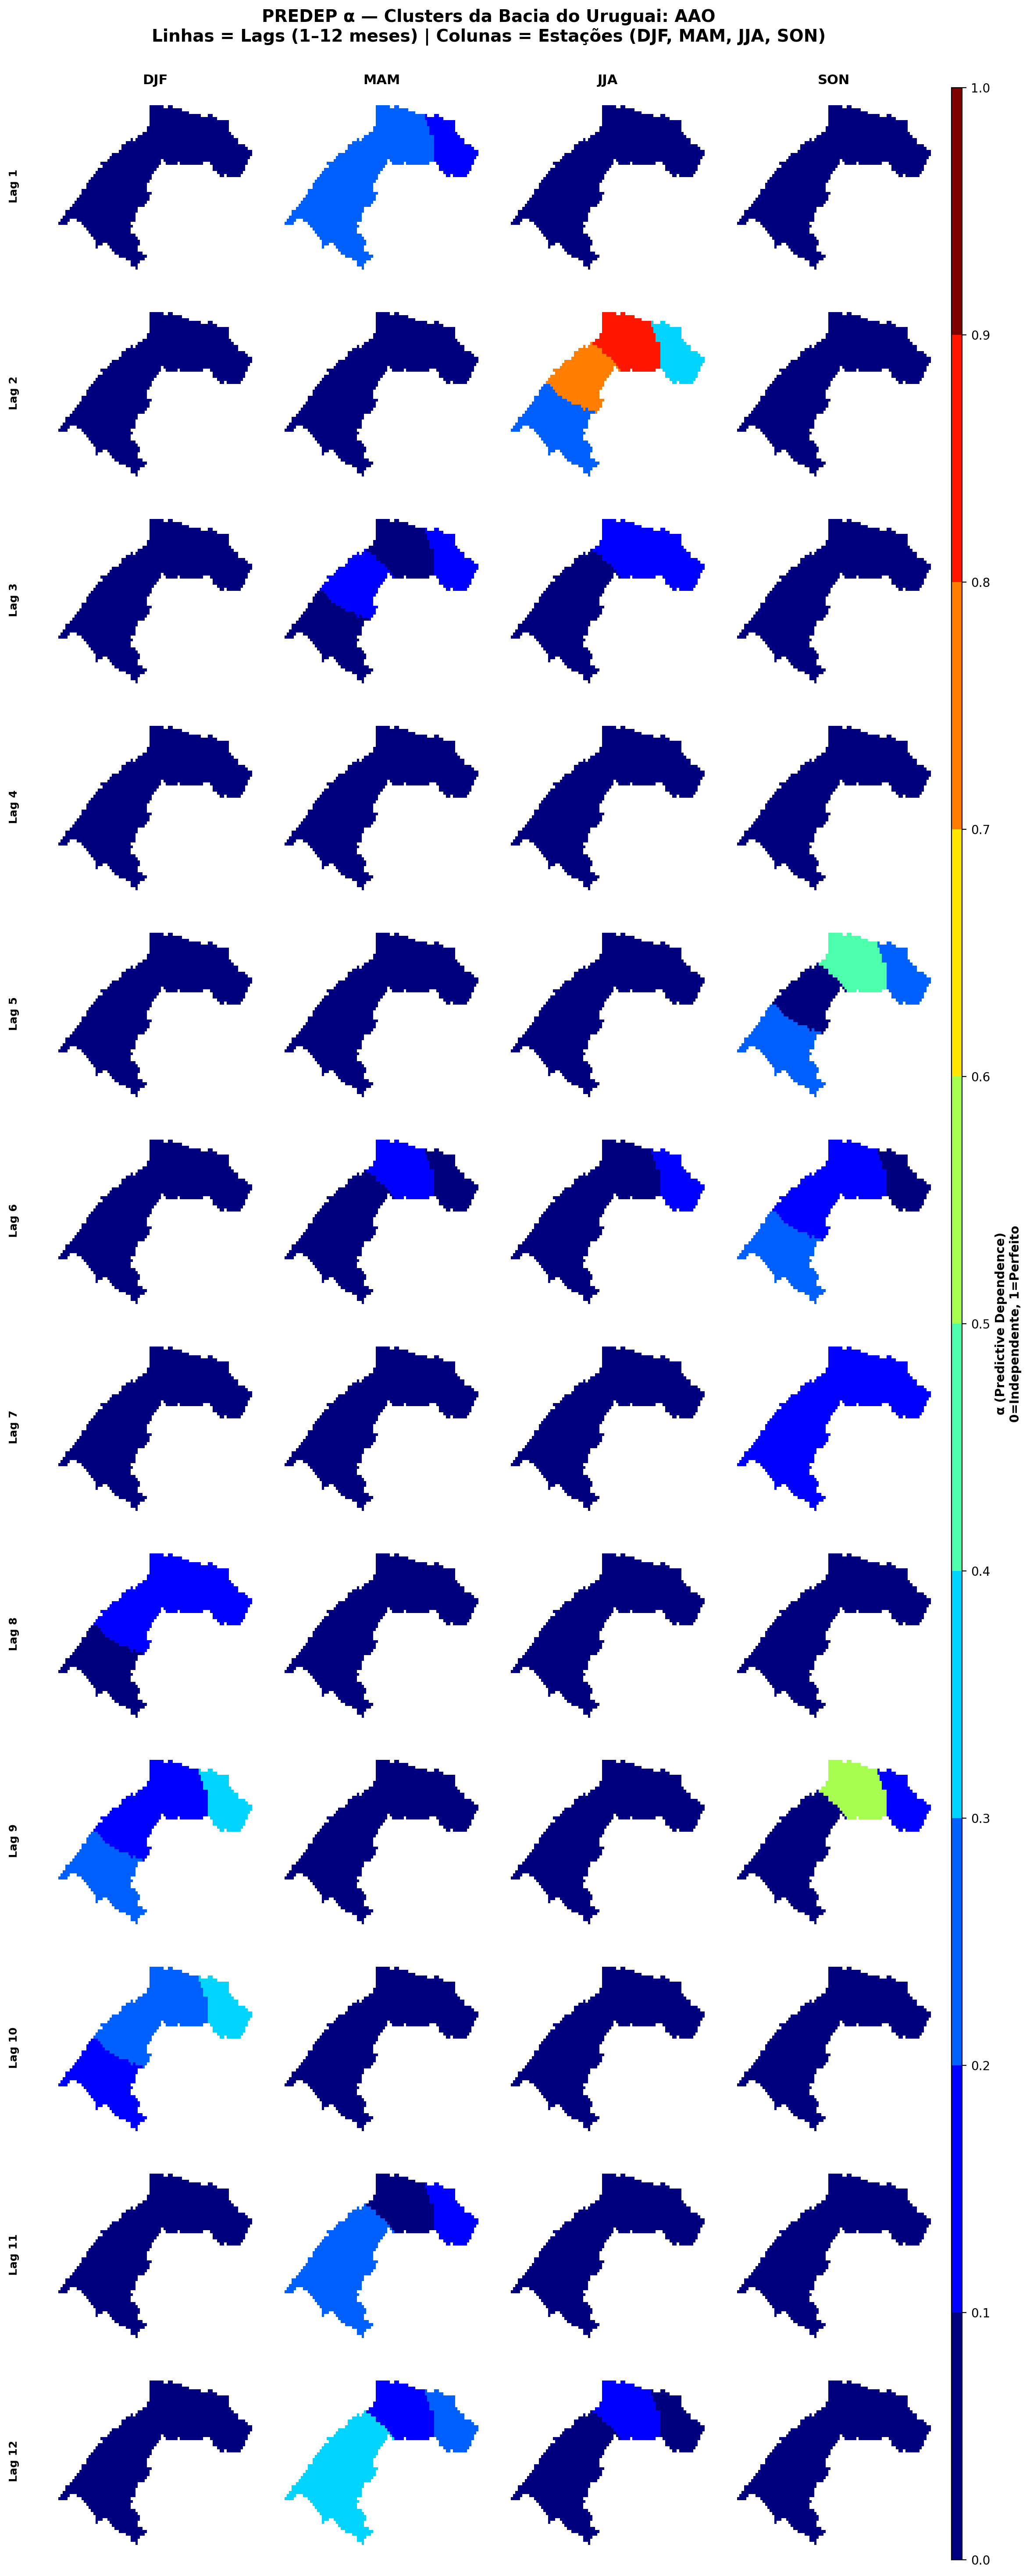

In [41]:
outs_12x4 = {}
for mov, alpha in all_data.items():
    print(f'Gerando plot todos os lags: {mov}...')
    out = plot_12x4_all_lags_clusters(alpha, mov, cluster_names, output_dir)
    outs_12x4[mov] = out
    display(Image(filename=str(out)))

## 5. Estatísticas dos Resultados

In [42]:
print('ESTATÍSTICAS POR MOV E ESTAÇÃO\n' + '='*60)

for mov, alpha in all_data.items():
    print(f'\n{mov}:')
    for s_idx, season in enumerate(SEASONS):
        a_s = alpha[s_idx]   # (n_clusters, N_LAGS)
        valid_lags = []
        for li, lag in enumerate(range(1, N_LAGS + 1)):
            vals = a_s[:, li]
            if not np.all(np.isnan(vals)):
                valid_lags.append(f'L{lag}={np.nanmean(vals):.2f}')
        if valid_lags:
            print(f'  {season}: α médio por lag — ' + '  '.join(valid_lags))
        else:
            print(f'  {season}: sem dados válidos')

ESTATÍSTICAS POR MOV E ESTAÇÃO

AAO:
  DJF: α médio por lag — L1=-0.03  L2=-0.03  L3=-0.00  L4=-0.03  L5=-0.05  L6=-0.03  L7=-0.03  L8=0.13  L9=0.24  L10=0.24  L11=0.02  L12=0.02
  MAM: α médio por lag — L1=0.21  L2=-0.03  L3=0.08  L4=-0.01  L5=-0.04  L6=0.06  L7=-0.01  L8=-0.00  L9=-0.07  L10=-0.02  L11=0.17  L12=0.26
  JJA: α médio por lag — L1=-0.03  L2=0.55  L3=0.09  L4=0.07  L5=0.01  L6=0.02  L7=-0.04  L8=0.00  L9=0.05  L10=-0.02  L11=-0.04  L12=0.00
  SON: α médio por lag — L1=-0.04  L2=-0.05  L3=-0.04  L4=-0.04  L5=0.25  L6=0.12  L7=0.16  L8=-0.00  L9=0.18  L10=-0.01  L11=-0.02  L12=0.06


## 6. Análise de Lags Ótimos

In [43]:
print('LAGS ÓTIMOS POR MOV, ESTAÇÃO E CLUSTER\n' + '='*60)

for mov, alpha in all_data.items():
    print(f'\n{mov}:')
    for s_idx, season in enumerate(SEASONS):
        a_s = alpha[s_idx]
        if np.all(np.isnan(a_s)):
            print(f'  {season}: sem dados')
            continue
        mean_by_lag = np.nanmean(a_s, axis=0)
        if np.all(np.isnan(mean_by_lag)):
            print(f'  {season}: sem dados')
            continue
        opt_li  = int(np.nanargmax(mean_by_lag))
        opt_lag = opt_li + 1   # 1-based
        print(f'  {season}: lag ótimo médio = {opt_lag} '
              f'(α={mean_by_lag[opt_li]:.3f})')
        for ci, cname in enumerate(short_names):
            vals = a_s[ci]
            if not np.all(np.isnan(vals)):
                best_li  = int(np.nanargmax(vals))
                best_lag = best_li + 1
                top3_li  = list(np.argsort(np.where(np.isnan(vals), -999, vals))[-3:][::-1])
                top3_lag = [l + 1 for l in top3_li]
                print(f'    {cname}: Lag {best_lag} '
                      f'(α={vals[best_li]:.3f}) | top3={top3_lag}')
            else:
                print(f'    {cname}: sem dados')

LAGS ÓTIMOS POR MOV, ESTAÇÃO E CLUSTER

AAO:
  DJF: lag ótimo médio = 10 (α=0.239)
    C1: Lag 9 (α=0.241) | top3=[9, 10, 8]
    C2: Lag 10 (α=0.234) | top3=[10, 9, 8]
    C4: Lag 10 (α=0.354) | top3=[10, 9, 8]
    C3: Lag 10 (α=0.218) | top3=[10, 9, 8]
  MAM: lag ótimo médio = 12 (α=0.262)
    C1: Lag 12 (α=0.374) | top3=[12, 1, 11]
    C2: Lag 12 (α=0.321) | top3=[12, 11, 1]
    C4: Lag 12 (α=0.222) | top3=[12, 11, 3]
    C3: Lag 1 (α=0.244) | top3=[1, 12, 6]
  JJA: lag ótimo médio = 2 (α=0.553)
    C1: Lag 2 (α=0.262) | top3=[2, 6, 3]
    C2: Lag 2 (α=0.796) | top3=[2, 4, 8]
    C4: Lag 2 (α=0.349) | top3=[2, 3, 6]
    C3: Lag 2 (α=0.803) | top3=[2, 3, 12]
  SON: lag ótimo médio = 5 (α=0.248)
    C1: Lag 5 (α=0.244) | top3=[5, 6, 7]
    C2: Lag 6 (α=0.161) | top3=[6, 7, 5]
    C4: Lag 5 (α=0.275) | top3=[5, 9, 7]
    C3: Lag 9 (α=0.554) | top3=[9, 5, 7]


## 7. Resumo Final

In [44]:
print('\n' + '='*60)
print('VISUALIZAÇÃO CONCLUÍDA')
print('='*60)
print(f'\nArquivos gerados em: {output_dir}')
for mov in all_data:
    if mov in outs_4x4:
        print(f'  {mov} lags ótimos: {outs_4x4[mov].name}')
    if mov in outs_12x4:
        print(f'  {mov} todos lags: {outs_12x4[mov].name}')
print(f'\nClusters: {short_names}')
print(f'Estações: {SEASONS}')
print(f'MoVs: {list(all_data.keys())}')
print(f'Lags: 1–{N_LAGS}')


VISUALIZAÇÃO CONCLUÍDA

Arquivos gerados em: ../results/predep_uruguai/plots
  AAO lags ótimos: optimal_lag_seasons_AAO.png
  AAO todos lags: predep_all_lags_seasons_AAO.png

Clusters: ['C1', 'C2', 'C4', 'C3']
Estações: ['DJF', 'MAM', 'JJA', 'SON']
MoVs: ['AAO']
Lags: 1–12
